In [1]:
%pip install transformers

  Using cached regex-2026.9.29-cp312-cp312-macosx_11_0_arm64.whl.metadata (40 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-macosx_11_0_arm64.whl.metadata (9.8 kB)
  Using cached safetensors-0.8.0-cp310-abi3-macosx_11_0_arm64.whl.metadata (4.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 1.8 MB/s  0:00:07m0:00:0100:01
Using cached tokenizers-0.23.3-cp310-abi3-macosx_11_0_arm64.whl (3.1 MB)
Using cached regex-2026.9.29-cp312-cp312-macosx_11_0_arm64.whl (293 kB)
Using cached safetensors-0.8.0-cp310-abi3-macosx_11_0_arm64.whl (484 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [transformers] [transformers]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import torch
import transformers

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

if torch.cuda.is_available():
    dispositivo = "cuda"
elif torch.backends.mps.is_available():
    dispositivo = "mps"
else:
    dispositivo = "cpu"

print("Dispositivo disponible:", dispositivo)

/opt/anaconda3/envs/poemas-ia/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /opt/anaconda3/envs/poemas-ia/bin/python
PyTorch: 2.14.1
Transformers: 5.20.0
Dispositivo disponible: mps


In [3]:
import random
import numpy as np
from datasets import load_dataset
from transformers import set_seed

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

device = torch.device(dispositivo)

CLASES = {
    0: "negative",
    1: "positive",
    2: "no_impact",
}

dataset = load_dataset(
    "google-research-datasets/poem_sentiment"
)

datos = {
    particion: dataset[particion].to_pandas().loc[
        lambda df: df["label"].isin(CLASES)
    ].copy()
    for particion in ("train", "validation")
}

train_df = datos["train"]
val_df = datos["validation"]

print("Entrenamiento:", len(train_df))
print("Validación:", len(val_df))

Entrenamiento: 843
Validación: 105


In [4]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODELO_BASE = "distilbert/distilbert-base-uncased"

tokenizador = AutoTokenizer.from_pretrained(MODELO_BASE)

modelo_bert = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE,
    num_labels=len(CLASES),
    id2label=CLASES,
    label2id={
        nombre: indice
        for indice, nombre in CLASES.items()
    }
).to(device)

# Comprobar que el modelo puede procesar un verso.
entrada = tokenizador(
    train_df.iloc[0]["verse_text"],
    return_tensors="pt",
    truncation=True,
    max_length=64
).to(device)

modelo_bert.eval()

with torch.no_grad():
    salida = modelo_bert(**entrada)

print("Dispositivo:", next(modelo_bert.parameters()).device)
print("Forma de salida:", salida.logits.shape)
print("Etiquetas:", modelo_bert.config.id2label)

W1015 13:50:08.650000 29551 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 22696.45it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your 

Dispositivo: mps:0
Forma de salida: torch.Size([1, 3])
Etiquetas: {0: 'negative', 1: 'positive', 2: 'no_impact'}


In [5]:
from torch.utils.data import Dataset, DataLoader

MAX_LEN_BERT = 64
BATCH_SIZE = 16

class DatasetVersosBert(Dataset):
    def __init__(self, dataframe):
        self.textos = dataframe["verse_text"].tolist()
        self.etiquetas = dataframe["label"].tolist()

    def __len__(self):
        return len(self.textos)

    def __getitem__(self, indice):
        entrada = tokenizador(
            self.textos[indice],
            truncation=True,
            padding="max_length",
            max_length=MAX_LEN_BERT,
            return_tensors="pt"
        )

        ejemplo = {
            clave: valor.squeeze(0)
            for clave, valor in entrada.items()
        }

        ejemplo["labels"] = torch.tensor(
            self.etiquetas[indice],
            dtype=torch.long
        )

        return ejemplo

generador = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    DatasetVersosBert(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generador,
    num_workers=0
)

val_loader = DataLoader(
    DatasetVersosBert(val_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

lote = next(iter(train_loader))

for nombre, tensor in lote.items():
    print(nombre, tensor.shape)

input_ids torch.Size([16, 64])
token_type_ids torch.Size([16, 64])
attention_mask torch.Size([16, 64])
labels torch.Size([16])


In [6]:
from pathlib import Path
import pandas as pd
from torch import nn
from sklearn.metrics import f1_score, classification_report

# Pesos calculados únicamente con entrenamiento.
conteos = (
    train_df["label"]
    .value_counts()
    .reindex(list(CLASES))
    .to_numpy()
)

pesos_bert = len(train_df) / (len(CLASES) * conteos)

criterio = nn.CrossEntropyLoss(
    weight=torch.tensor(
        pesos_bert,
        dtype=torch.float32,
        device=device
    )
)

optimizador = torch.optim.AdamW(
    modelo_bert.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

def preparar_lote(lote):
    entradas = {
        clave: lote[clave].to(device)
        for clave in ("input_ids", "attention_mask")
    }
    etiquetas = lote["labels"].to(device)
    return entradas, etiquetas

def evaluar_bert(modelo, loader):
    modelo.eval()
    reales, predichas = [], []

    with torch.no_grad():
        for lote in loader:
            entradas, etiquetas = preparar_lote(lote)
            logits = modelo(**entradas).logits

            reales.extend(etiquetas.cpu().tolist())
            predichas.extend(
                logits.argmax(dim=1).cpu().tolist()
            )

    f1 = f1_score(
        reales,
        predichas,
        labels=list(CLASES),
        average="macro",
        zero_division=0
    )

    return f1, reales, predichas

carpeta_bert = Path("artifacts/modelo_distilbert")
carpeta_bert.mkdir(parents=True, exist_ok=True)
ruta_pesos = carpeta_bert / "mejores_pesos.pt"

historial_bert = []
mejor_f1_bert = -1.0
mejor_epoca_bert = 0
sin_mejora = 0

for epoca in range(1, 9):
    modelo_bert.train()
    suma_perdidas = 0.0

    print(f"\nIniciando época {epoca}...", flush=True)

    for paso, lote in enumerate(train_loader, start=1):
        entradas, etiquetas = preparar_lote(lote)

        optimizador.zero_grad()
        logits = modelo_bert(**entradas).logits
        perdida = criterio(logits, etiquetas)

        perdida.backward()
        nn.utils.clip_grad_norm_(
            modelo_bert.parameters(), max_norm=1.0
        )
        optimizador.step()

        suma_perdidas += perdida.item()

        if paso % 20 == 0:
            print(
                f"  Lote {paso}/{len(train_loader)}",
                flush=True
            )

    perdida_media = suma_perdidas / len(train_loader)
    f1_val, _, _ = evaluar_bert(modelo_bert, val_loader)

    historial_bert.append({
        "epoca": epoca,
        "perdida_train": perdida_media,
        "f1_macro_val": f1_val
    })

    print(
        f"Época {epoca:02d} | "
        f"Loss train: {perdida_media:.4f} | "
        f"F1 val: {f1_val:.4f}",
        flush=True
    )

    if f1_val > mejor_f1_bert:
        mejor_f1_bert = f1_val
        mejor_epoca_bert = epoca
        sin_mejora = 0

        # Copia independiente en CPU para guardar el checkpoint.
        estado_cpu = {
            nombre: tensor.detach().cpu().clone()
            for nombre, tensor in modelo_bert.state_dict().items()
        }
        torch.save(estado_cpu, ruta_pesos)
        del estado_cpu
    else:
        sin_mejora += 1

    if sin_mejora >= 2:
        print("Detención temprana.")
        break

# Recuperar la mejor época.
modelo_bert.load_state_dict(
    torch.load(
        ruta_pesos,
        map_location="cpu",
        weights_only=True
    )
)

f1_bert, reales_bert, pred_bert = evaluar_bert(
    modelo_bert, val_loader
)

pd.DataFrame(historial_bert).to_csv(
    carpeta_bert / "historial.csv",
    index=False
)

print(f"\nMejor época: {mejor_epoca_bert}")
print(f"F1 macro de validación: {f1_bert:.4f}\n")

print(classification_report(
    reales_bert,
    pred_bert,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    digits=4,
    zero_division=0
))


Iniciando época 1...
  Lote 20/53
  Lote 40/53
Época 01 | Loss train: 1.0478 | F1 val: 0.6801

Iniciando época 2...
  Lote 20/53
  Lote 40/53
Época 02 | Loss train: 0.5638 | F1 val: 0.8278

Iniciando época 3...
  Lote 20/53
  Lote 40/53
Época 03 | Loss train: 0.2020 | F1 val: 0.8230

Iniciando época 4...
  Lote 20/53
  Lote 40/53
Época 04 | Loss train: 0.0688 | F1 val: 0.8156
Detención temprana.

Mejor época: 2
F1 macro de validación: 0.8278

              precision    recall  f1-score   support

    negative     0.7727    0.8947    0.8293        19
    positive     0.8462    0.6471    0.7333        17
   no_impact     0.9143    0.9275    0.9209        69

    accuracy                         0.8762       105
   macro avg     0.8444    0.8231    0.8278       105
weighted avg     0.8776    0.8762    0.8739       105



In [7]:
import json
import platform
import transformers

# Guardar en formato reutilizable con from_pretrained().
modelo_bert.save_pretrained(
    carpeta_bert,
    safe_serialization=True
)
tokenizador.save_pretrained(carpeta_bert)

registro = {
    "modelo_base": MODELO_BASE,
    "semilla": SEED,
    "clases": CLASES,
    "clase_excluida": "mixed",
    "max_length": MAX_LEN_BERT,
    "batch_size": BATCH_SIZE,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "pesos_clases": pesos_bert.tolist(),
    "mejor_epoca": mejor_epoca_bert,
    "f1_macro_validacion": float(f1_bert),
    "reporte_validacion": classification_report(
        reales_bert,
        pred_bert,
        labels=list(CLASES),
        target_names=list(CLASES.values()),
        output_dict=True,
        zero_division=0
    ),
    "python": platform.python_version(),
    "pytorch": str(torch.__version__),
    "transformers": transformers.__version__,
    "dispositivo_entrenamiento": str(device),
    "prueba_evaluada": False
}

with open(
    carpeta_bert / "resultados.json", "w", encoding="utf-8"
) as archivo:
    json.dump(registro, archivo, ensure_ascii=False, indent=2)

predicciones_bert = val_df[
    ["id", "verse_text", "label"]
].copy()

predicciones_bert["prediccion"] = pred_bert
predicciones_bert.to_csv(
    carpeta_bert / "predicciones_validacion.csv",
    index=False
)

print("Modelo, tokenizador y resultados guardados en:")
print(carpeta_bert.resolve())

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.14it/s]

Modelo, tokenizador y resultados guardados en:
/Users/luisvazquez/Desktop/LAVP/Diplomado IA - CIC/PROYECTO_FINAL/Análisis de sentimientos en versos/poem-sentiment-v2/artifacts/modelo_distilbert


In [8]:
# Preparar prueba con las mismas clases del experimento.
test_df = dataset["test"].to_pandas().loc[
    lambda df: df["label"].isin(CLASES)
].copy()

test_loader = DataLoader(
    DatasetVersosBert(test_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# modelo_bert conserva los pesos de la mejor época.
f1_test_bert, reales_test_bert, pred_test_bert = evaluar_bert(
    modelo_bert,
    test_loader
)

print("Versos de prueba:", len(test_df))
print(f"F1 macro de prueba: {f1_test_bert:.4f}\n")

reporte_test_bert = classification_report(
    reales_test_bert,
    pred_test_bert,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    output_dict=True,
    zero_division=0
)

print(classification_report(
    reales_test_bert,
    pred_test_bert,
    labels=list(CLASES),
    target_names=list(CLASES.values()),
    digits=4,
    zero_division=0
))

Versos de prueba: 104
F1 macro de prueba: 0.8140

              precision    recall  f1-score   support

    negative     0.7500    0.9474    0.8372        19
    positive     0.8333    0.6250    0.7143        16
   no_impact     0.8971    0.8841    0.8905        69

    accuracy                         0.8558       104
   macro avg     0.8268    0.8188    0.8140       104
weighted avg     0.8604    0.8558    0.8537       104



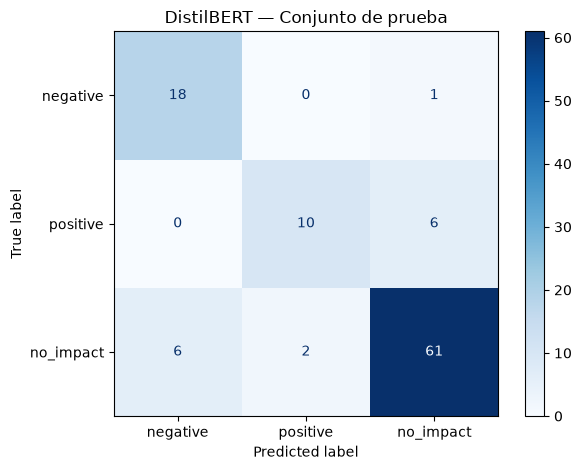

Resultados de prueba guardados.


In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    reales_test_bert,
    pred_test_bert,
    labels=list(CLASES),
    display_labels=list(CLASES.values()),
    cmap="Blues",
    values_format="d"
)

plt.title("DistilBERT — Conjunto de prueba")
plt.tight_layout()
plt.savefig(
    carpeta_bert / "matriz_confusion_test.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Actualizar el registro conservando las métricas de validación.
ruta_resultados = carpeta_bert / "resultados.json"

with open(ruta_resultados, encoding="utf-8") as archivo:
    registro = json.load(archivo)

registro.update({
    "prueba_evaluada": True,
    "f1_macro_prueba": float(f1_test_bert),
    "reporte_prueba": reporte_test_bert
})

with open(ruta_resultados, "w", encoding="utf-8") as archivo:
    json.dump(registro, archivo, ensure_ascii=False, indent=2)

predicciones_test = test_df[
    ["id", "verse_text", "label"]
].copy()

predicciones_test["prediccion"] = pred_test_bert
predicciones_test.to_csv(
    carpeta_bert / "predicciones_test.csv",
    index=False
)

print("Resultados de prueba guardados.")

In [10]:
from sklearn.metrics import confusion_matrix

print(f"F1 macro de prueba: {f1_test_bert:.4f}\n")

display(pd.DataFrame(
    confusion_matrix(
        reales_test_bert,
        pred_test_bert,
        labels=list(CLASES)
    ),
    index=[f"Real: {nombre}" for nombre in CLASES.values()],
    columns=[f"Predicho: {nombre}" for nombre in CLASES.values()]
))

F1 macro de prueba: 0.8140



,Predicho: negative,Predicho: positive,Predicho: no_impact
Real: negative,18,0,1
Real: positive,0,10,6
Real: no_impact,6,2,61


In [11]:
muestra = pd.read_csv(
    carpeta_bert / "predicciones_test.csv"
)

# Un ejemplo por clase real, sin seleccionar solo aciertos.
muestra = muestra.groupby("label", sort=True).head(1).copy()

muestra["sentimiento_real"] = muestra["label"].map(CLASES)
muestra["prediccion_guardada"] = muestra["prediccion"].map(CLASES)

with pd.option_context("display.max_colwidth", None):
    display(muestra[
        ["verse_text", "sentimiento_real", "prediccion_guardada"]
    ])

,verse_text,sentimiento_real,prediccion_guardada
0,"my canoe to make more steady,",no_impact,no_impact
1,and be glad in the summer morning when the kindred ride on their way;,positive,positive
5,indignantly i hurled the cry:,negative,negative
